### **Image preprocessing**

In [21]:
import warnings
warnings.filterwarnings("ignore")

In [22]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import PIL as pillow
from PIL import Image
from skimage.util import random_noise
from skimage.restoration import denoise_tv_chambolle
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
from torchvision.utils import make_grid
from torchvision.datasets import ImageFolder
from torchvision import models, transforms, datasets
from sklearn.metrics import confusion_matrix

| Feature             | OpenCV                                        | Pillow (PIL)                   |
| ------------------- | --------------------------------------------- | ------------------------------ |
| Read an image       | `cv2.imread(path, cv2.IMREAD_COLOR)`          | `Image.open(path)`             |
| Underlying format   | NumPy array, dtype = `uint8`, shape = (H×W×3) | `PIL.Image.Image` object       |
| Color channel order | BGR                                           | RGB                            |
| Convert to RGB      | `cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)`    | `img = img.convert("RGB")`     |
| Save an image       | `cv2.imwrite(path, img_bgr)`                  | `img.save(path, format="PNG")` |

In [23]:
# OpenCV
# სურათის წაკთხვა (BGR)
img_bgr = cv2.imread("../../images/lenna.png", cv2.IMREAD_COLOR)  # np.array
# Convert to RGB 
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# სურათის შენახვა
cv2.imwrite("../../images/out.png", img_bgr)

True

In [24]:
# Pillow
# სურათის წაკითხვა
img = Image.open("../../images/lenna.png")  
# Convert to RGB 
img = img.convert("RGB")

# სურათის შენახვა
img.save("out.png", format="PNG")

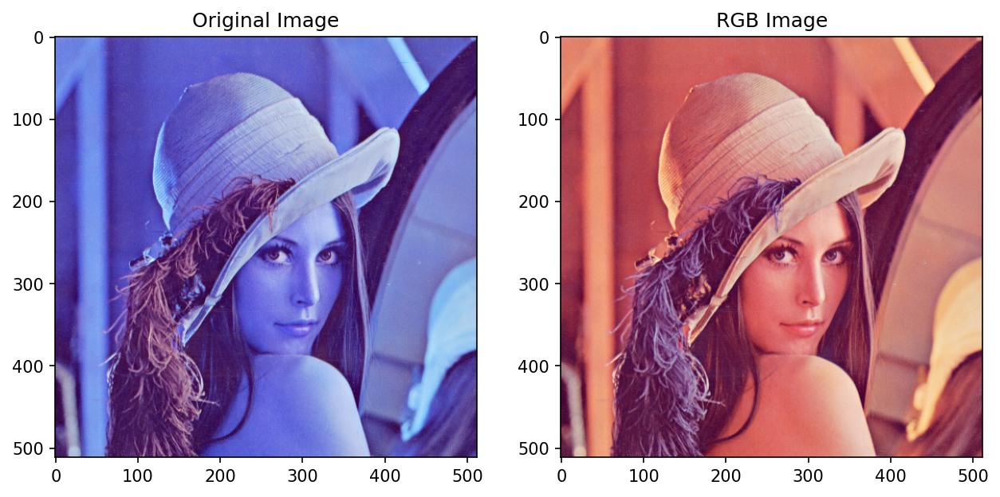

In [25]:
fig, ax = plt.subplots(figsize=(10, 5), ncols=2, dpi=150)
ax[0].imshow(img_bgr)
ax[0].set_title("Original Image")
ax[1].imshow(img_rgb)
ax[1].set_title("RGB Image");

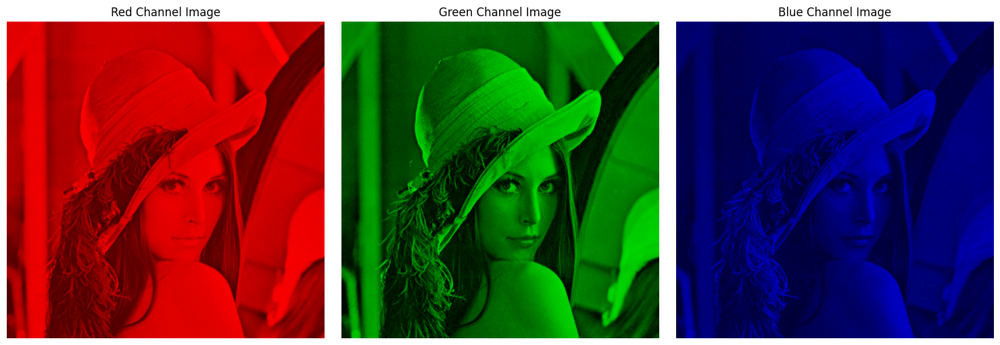

In [26]:
# RGB channels, თითოეული არხი 
r = img_rgb[:, :, 0]
g = img_rgb[:, :, 1]
b = img_rgb[:, :, 2]

# Create 3 color-highlighted images
r_img = np.zeros_like(img_rgb)
g_img = np.zeros_like(img_rgb)
b_img = np.zeros_like(img_rgb)
r_img[:, :, 0] = r
g_img[:, :, 1] = g
b_img[:, :, 2] = b

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, chan_img, title in zip(axes, [r_img, g_img, b_img], 
                                ["Red Channel Image", "Green Channel Image", "Blue Channel Image"]):
    ax.imshow(chan_img)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

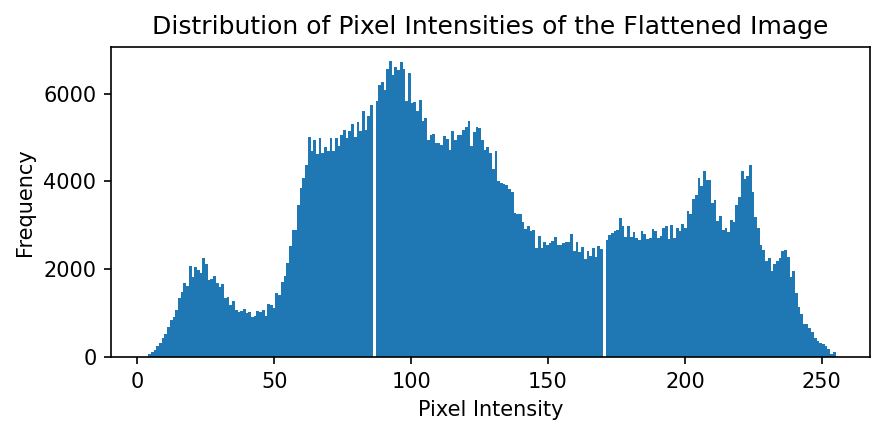

In [27]:
# პიქსელების მნიშვნელობების განაწილება
fig, ax = plt.subplots(figsize=(6, 3), dpi=150)
ax.hist(img_rgb.flatten(), bins=255)
ax.set_title("Distribution of Pixel Intensities of the Flattened Image")
ax.set_xlabel("Pixel Intensity")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show();

### Color-based Features

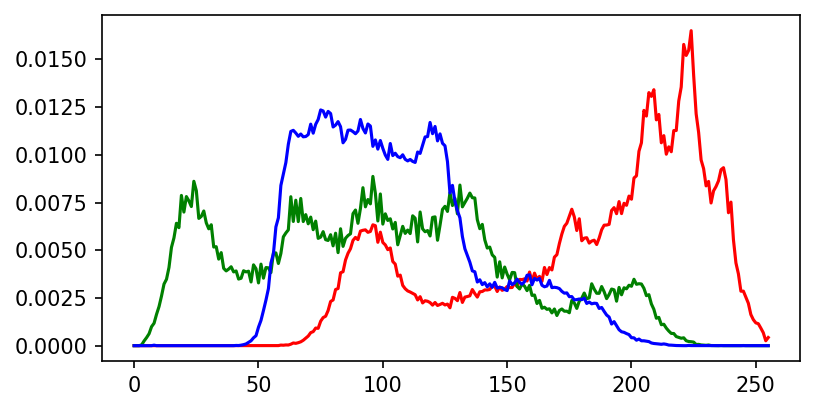

In [28]:
# Color Histograms
# Compute 256-bin histograms for each channel
hist_r = cv2.calcHist([img_rgb], [0], None, [256], [0,256])
hist_g = cv2.calcHist([img_rgb], [1], None, [256], [0,256])
hist_b = cv2.calcHist([img_rgb], [2], None, [256], [0,256])

#  Normalize so sum(hist)=1
hist_r /= hist_r.sum()
hist_g /= hist_g.sum()
hist_b /= hist_b.sum()

fig, ax = plt.subplots(figsize=(6, 3), dpi=150)
ax.plot(hist_r.flatten(), color="red")
ax.plot(hist_g.flatten(), color="green")
ax.plot(hist_b.flatten(), color="blue");

In [29]:
# Color Moments
# Flatten each channel to a 1D array
r = img_rgb[:,:,0].flatten().astype(np.float64)
g = img_rgb[:,:,1].flatten().astype(np.float64)
b = img_rgb[:,:,2].flatten().astype(np.float64)

# თითოეული არხისთვის მახასიათებლები
features = {}
for name, channel in (("R", r), ("G", g), ("B", b)):
    min_v = channel.min()
    max_v = channel.max()
    median = np.median(channel)
    mean = channel.mean()
    var  = channel.var()
    # skewness: E[(X-μ)^3] / σ^3
    skew = ((channel - mean)**3).mean() / (channel.std()**3)
    features[name] = (min_v, max_v, mean, median, var, skew)

pd.DataFrame(features, index=["min", "max", "mean", "median", "std", "skewness"])

,R,G,B
min,54.000000,3.000000,8.000000
max,255.000000,248.000000,225.000000
mean,180.223660,99.051216,105.410252
median,197.000000,97.000000,100.000000
std,2405.782279,2796.031839,1159.942217
skewness,-0.701058,0.222995,0.680268


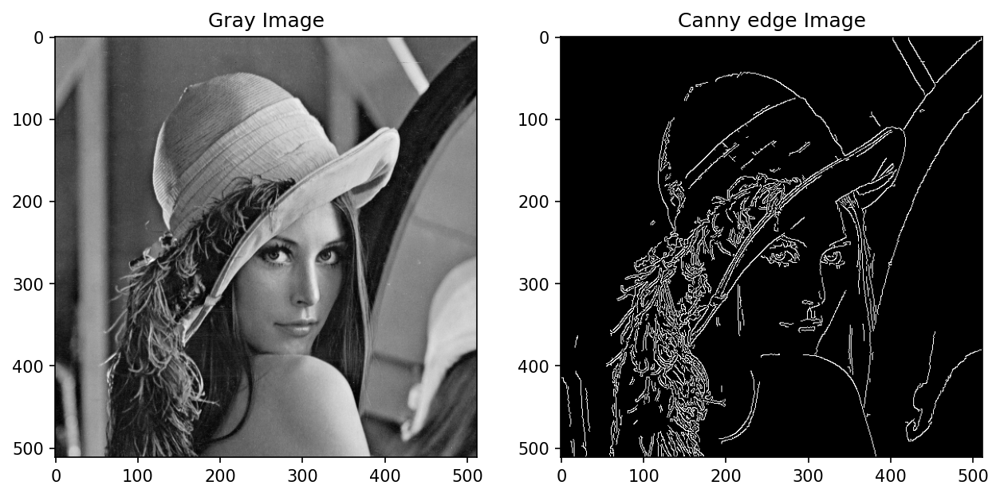

In [30]:
# Convert to graycsale
img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2GRAY)
# Blur the image for better edge detection
img_blur = cv2.GaussianBlur(img_gray, (3,3), 0) 
# Canny edges
edges = cv2.Canny(img_gray, 100, 200)

fig, ax = plt.subplots(figsize=(10, 5), ncols=2, dpi=150)
ax[0].imshow(img_gray, cmap = "gray")
ax[0].set_title("Gray Image")
ax[1].imshow(edges, cmap = "gray")
ax[1].set_title("Canny edge Image");

Text(0.5, 1.0, 'Sobel xy')

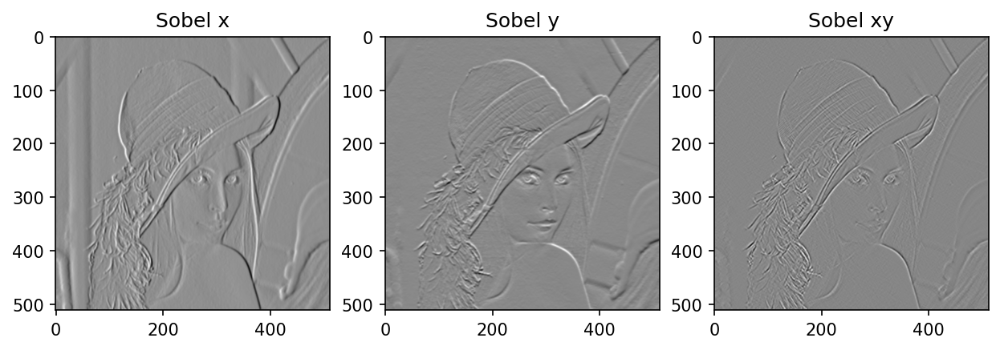

In [31]:
# Sobel Edge Detection
sobelx = cv2.Sobel(src=img_blur, ddepth=cv2.CV_64F, dx=1, dy=0, ksize=5) # Sobel Edge Detection on the X axis
sobely = cv2.Sobel(src=img_blur, ddepth=cv2.CV_64F, dx=0, dy=1, ksize=5) # Sobel Edge Detection on the Y axis
sobelxy = cv2.Sobel(src=img_blur, ddepth=cv2.CV_64F, dx=1, dy=1, ksize=5) # Combined X and Y Sobel Edge Detection

fig, ax = plt.subplots(figsize=(10, 5), ncols=3, dpi=150)
ax[0].imshow(sobelx, cmap = "gray")
ax[0].set_title("Sobel x")
ax[1].imshow(sobely, cmap = "gray")
ax[1].set_title("Sobel y")
ax[2].imshow(sobelxy, cmap = "gray")
ax[2].set_title("Sobel xy")

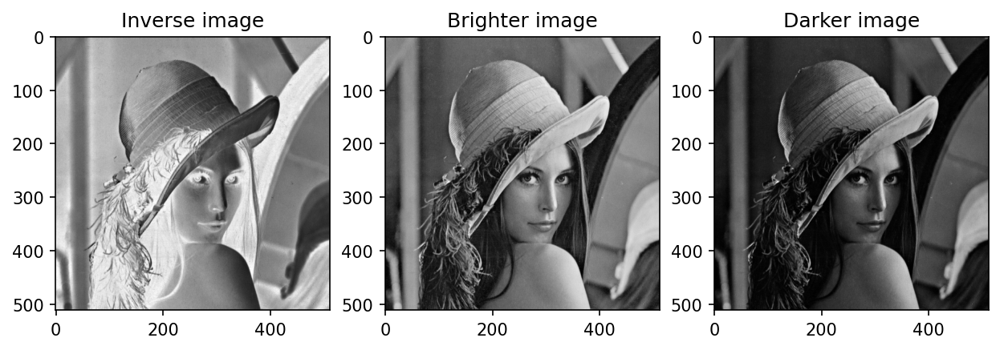

In [32]:
img_inverse = 255 - img_gray # bright pixels become dark, and the dark pixels become bright
img_bright = (100.0/255) * img_gray + 100 # all the pixels become brighter and a hazing-like effect of the image is generated
img_light = 255.0 * (img_gray / 255.0)**2 # The lightness level of the gray_image decreases after this step

fig, ax = plt.subplots(figsize=(10, 5), ncols=3, dpi=150)
ax[0].imshow(img_inverse, cmap = "gray")
ax[0].set_title("Inverse image")
ax[1].imshow(img_bright, cmap = "gray")
ax[1].set_title("Brighter image")
ax[2].imshow(img_light, cmap = "gray")
ax[2].set_title("Darker image");

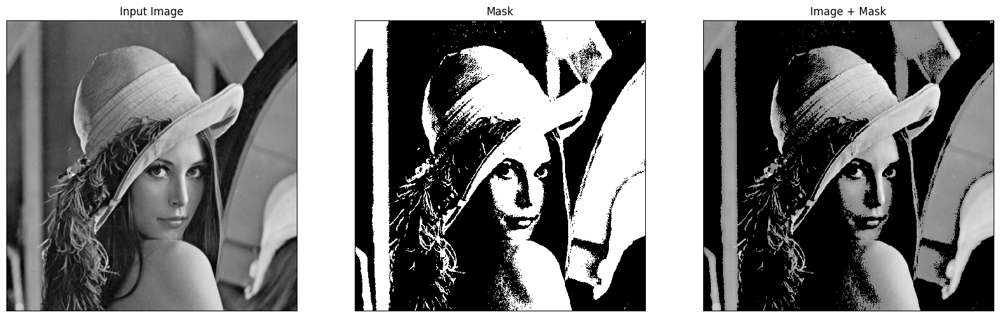

In [33]:
# Image Thresholding and Masks
_, mask = cv2.threshold(img_gray, thresh=120, maxval=255, type=cv2.THRESH_BINARY)
im_thresh_gray = cv2.bitwise_and(img_gray, mask)

plt.figure(figsize=([20, 20]))
plt.subplot(131),plt.imshow(img_gray, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(mask, interpolation='nearest', cmap='gray')
plt.title('Mask'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(im_thresh_gray, interpolation='nearest', cmap='gray')
plt.title('Image + Mask'), plt.xticks([]), plt.yticks([])
plt.show()

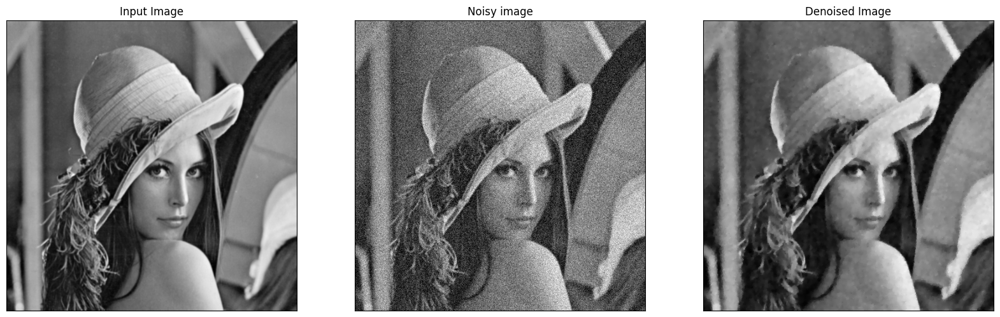

In [34]:
# Add noise to the image
noisy_image = random_noise(img_blur)

# Apply total variation filter denoising
denoised_image = denoise_tv_chambolle(noisy_image)

plt.figure(figsize=([20, 20]))
plt.subplot(131),plt.imshow(img_blur, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(noisy_image, cmap = 'gray')
plt.title('Noisy image'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(denoised_image, cmap = 'gray')
plt.title('Denoised Image'), plt.xticks([]), plt.yticks([])
plt.show()

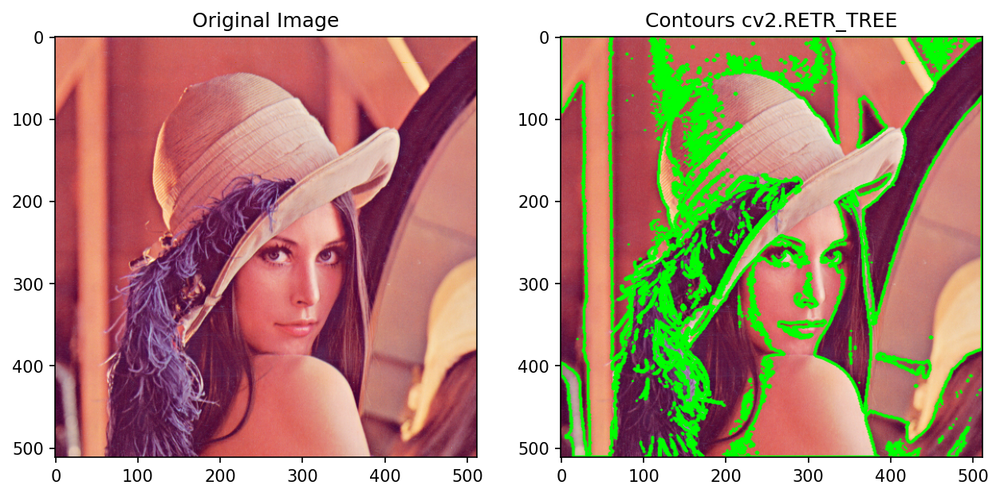

In [35]:
ret, thresh1 = cv2.threshold(img_gray, 100, 255, cv2.THRESH_BINARY)
contours2, hierarchy2 = cv2.findContours(thresh1, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
image_copy = img_rgb.copy()
cv2.drawContours(image_copy, contours2, -1, (0, 255, 0), 2, cv2.LINE_AA)

fig, ax = plt.subplots(figsize=(10, 5), ncols=2, dpi=150)
ax[0].imshow(img_rgb)
ax[0].set_title("Original Image")
ax[1].imshow(image_copy)
ax[1].set_title("Contours cv2.RETR_TREE");

In [36]:
# ნოირონული ქსელების საშუალებით სურათიდან მახასიათებლების წამოღება (Extracting CNN Feature Maps)
# ჩავტვირთოთ უკვე გაწვრთნილი მოდელი (vgg16), რომელსაც გადავცემთ სურათს და გამოვიყენებთ Feature Map-თვის
vgg = models.vgg16(pretrained=True)

# input-ის მომზადება, ისე რომ გადავცეთ vgg-ს. სურათის Pillow Image-ად გარდაქმნა
pil_img = Image.fromarray(img_rgb)

# Preprocessing pipeline for CNNs
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225]),
])
input_tensor = preprocess(pil_img).unsqueeze(0)

# Feature Map vgg-ის გამოყენებით
vgg.eval()
with torch.no_grad():
    feature_maps = vgg.features(input_tensor)

print("VGG16 feature maps shape:", feature_maps.shape) # torch.Size([1, 512, 7, 7])

VGG16 feature maps shape: torch.Size([1, 512, 7, 7])


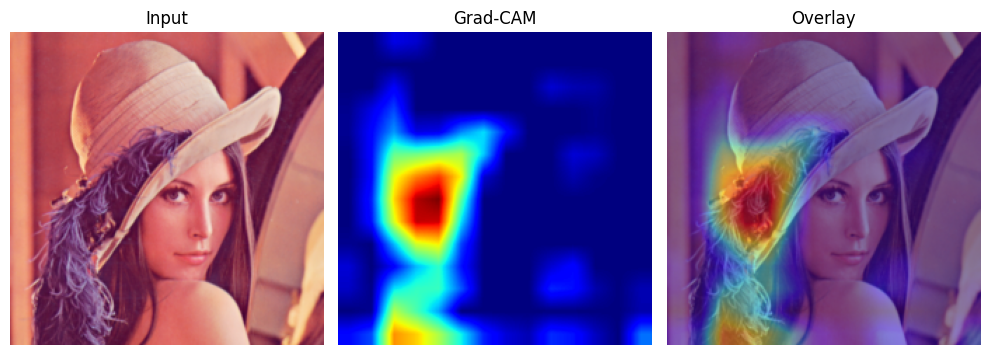

In [37]:
# disable inplace ReLU (prevents view+inplace issues)
for m in vgg.modules():
    if isinstance(m, torch.nn.ReLU):
        m.inplace = False

target_layer = vgg.features[28]  # last conv

def denorm_for_display(x_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406], device=x_tensor.device).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225], device=x_tensor.device).view(3,1,1)
    x = x_tensor * std + mean
    x = torch.clamp(x, 0, 1)
    return x.permute(1,2,0).detach().cpu().numpy()

def grad_cam(pil_img, class_idx=None):
    x = preprocess(pil_img).unsqueeze(0)  # [1,3,224,224]

    activ = None
    grad  = None

    # forward hook: capture activation tensor
    def fwd_hook(module, inp, out):
        nonlocal activ, grad
        activ = out  # [1,C,H,W]

        # tensor hook: capture gradient w.r.t. this activation
        def _save_grad(g):
            nonlocal grad
            grad = g.clone()   # <-- IMPORTANT: clone fixes view/inplace issue
        out.register_hook(_save_grad)

    handle = target_layer.register_forward_hook(fwd_hook)

    # forward
    logits = vgg(x)  # [1,1000]
    if class_idx is None:
        class_idx = int(logits.argmax(dim=1).item())

    # backward for selected class
    vgg.zero_grad(set_to_none=True)
    logits[0, class_idx].backward()

    handle.remove()

    # activ, grad shapes: [1,C,H,W]
    A  = activ[0]   # [C,H,W]
    dA = grad[0]    # [C,H,W]

    # weights = GAP over gradients
    weights = dA.mean(dim=(1,2))  # [C]

    cam = (weights[:, None, None] * A).sum(dim=0)  # [H,W]
    cam = F.relu(cam)

    cam -= cam.min()
    cam /= (cam.max() + 1e-8)

    cam = cam.unsqueeze(0).unsqueeze(0)  # [1,1,H,W]
    cam = F.interpolate(cam, size=(224,224), mode="bilinear", align_corners=False)
    cam = cam[0,0].detach().cpu().numpy()

    img_disp = denorm_for_display(x[0])
    return img_disp, cam, class_idx

def show_cam(img_disp, cam, alpha=0.45):
    plt.figure(figsize=(10,4))

    plt.subplot(1,3,1)
    plt.imshow(img_disp); plt.title("Input"); plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(cam, cmap="jet"); plt.title("Grad-CAM"); plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(img_disp)
    plt.imshow(cam, cmap="jet", alpha=alpha)
    plt.title("Overlay"); plt.axis("off")

    plt.tight_layout()
    plt.show()

img_disp, cam, pred_class = grad_cam(pil_img)
show_cam(img_disp, cam)

### Data Augmentation

In [40]:
def random_flip(image):
    # 0=vertical, 1=horizontal, -1=both
    mode = random.choice([-1, 0, 1])
    return cv2.flip(image, mode)

def random_rotate(image, max_angle=45):
    h, w = image.shape[:2]
    angle = random.uniform(-max_angle, max_angle)
    M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    return cv2.warpAffine(image, M, (w, h), borderMode=cv2.BORDER_REFLECT)

def random_translate(image, max_shift=0.2):
    h, w = image.shape[:2]
    tx = random.uniform(-max_shift, max_shift) * w
    ty = random.uniform(-max_shift, max_shift) * h
    M = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(image, M, (w, h), borderMode=cv2.BORDER_REFLECT)

def random_zoom(image, zoom_range=(0.5, 1.5)):
    h, w = image.shape[:2]
    zx, zy = np.random.uniform(*zoom_range, size=2)
    im = cv2.resize(image, None, fx=zx, fy=zy, interpolation=cv2.INTER_LINEAR)

    # compute how much to pad (if negative, means we’ll crop instead)
    pad_h, pad_w = max(h - im.shape[0], 0), max(w - im.shape[1], 0)
    im = np.pad(im,
                ((pad_h//2, pad_h - pad_h//2),
                 (pad_w//2, pad_w - pad_w//2),
                 (0, 0)),
                mode='reflect')

    # now center‐crop to (h, w)
    y_off, x_off = (im.shape[0] - h)//2, (im.shape[1] - w)//2
    return im[y_off:y_off+h, x_off:x_off+w]

def random_brightness_contrast(image, brightness=0.2, contrast=0.2):
    # brightness: ± as fraction of 255; contrast: ± fraction
    b = random.uniform(-brightness, brightness)*255
    c = 1.0 + random.uniform(-contrast, contrast)
    img_bc = cv2.convertScaleAbs(image, alpha=c, beta=b)
    return img_bc

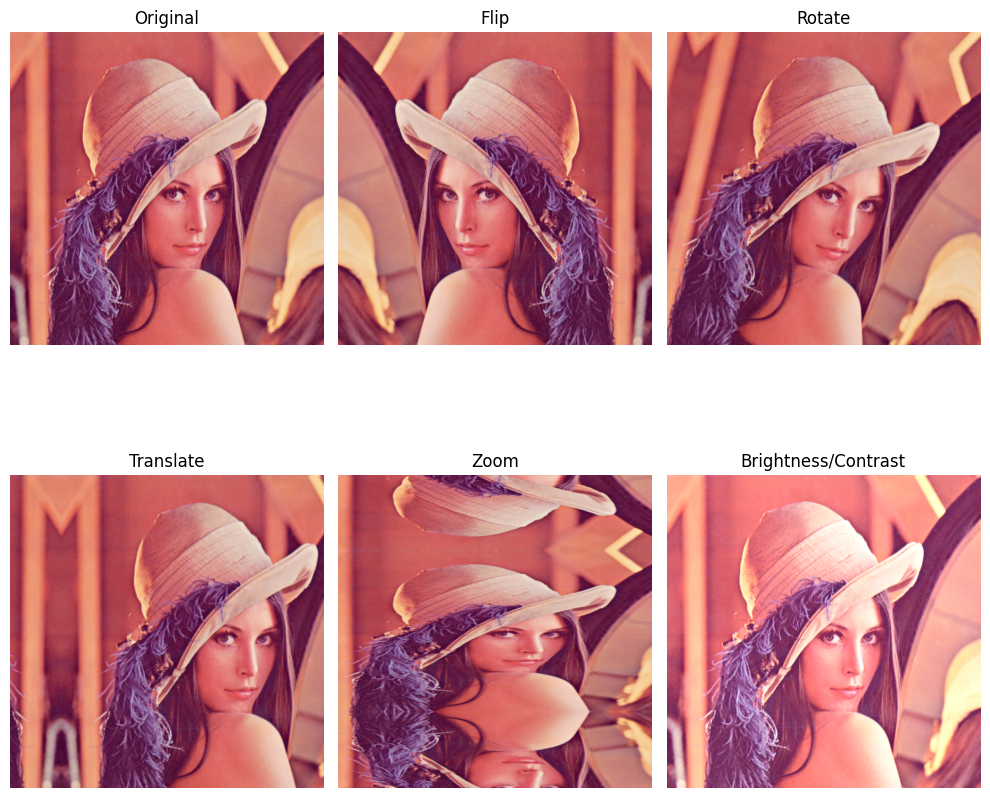

In [41]:
ops = [
    random_flip,
    random_rotate,
    random_translate,
    random_zoom,
    random_brightness_contrast
]

# Prepare images and titles for 3x3 grid
images = [img_bgr] + [op(img_bgr) for op in ops] 
# Titles
titles = [
    "Original", "Flip", "Rotate", "Translate",
    "Zoom", "Brightness/Contrast"
]

# Create 3x3 grid
fig, axes = plt.subplots(2, 3, figsize=(10, 10))
for ax, img_out, title in zip(axes.flatten(), images, titles):
    rgb = cv2.cvtColor(img_out, cv2.COLOR_BGR2RGB)
    ax.imshow(rgb)
    ax.axis('off')
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [42]:
COMMON_SIZE = (224, 224)

# ტრანსფორმაციების სია
transformations = [
    transforms.RandomRotation(degrees=(0, 45)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=0, scale=(0.5,2)),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.3)),
    transforms.ColorJitter(hue=0.05, saturation=0.05),
]

class MultiTransform:
    def __init__(self, transforms_list, size=COMMON_SIZE):
        # Build one Compose pipeline per augmentation
        self.pipelines = [
            transforms.Compose([
                transforms.Resize(size),
                aug,                  # the i-th augmentation
                transforms.ToTensor()
            ])
            for aug in transforms_list
        ]

    def __call__(self, img):
        # Simply apply each pipeline to the same PIL image
        return [pipeline(img) for pipeline in self.pipelines]

multi_tf = MultiTransform(transformations)
img_dataset = datasets.ImageFolder("../../datasets/images/classification/", transform=multi_tf)

In [43]:
images = img_dataset[0][0] + img_dataset[1][0] + img_dataset[-3][0] + img_dataset[-1][0]

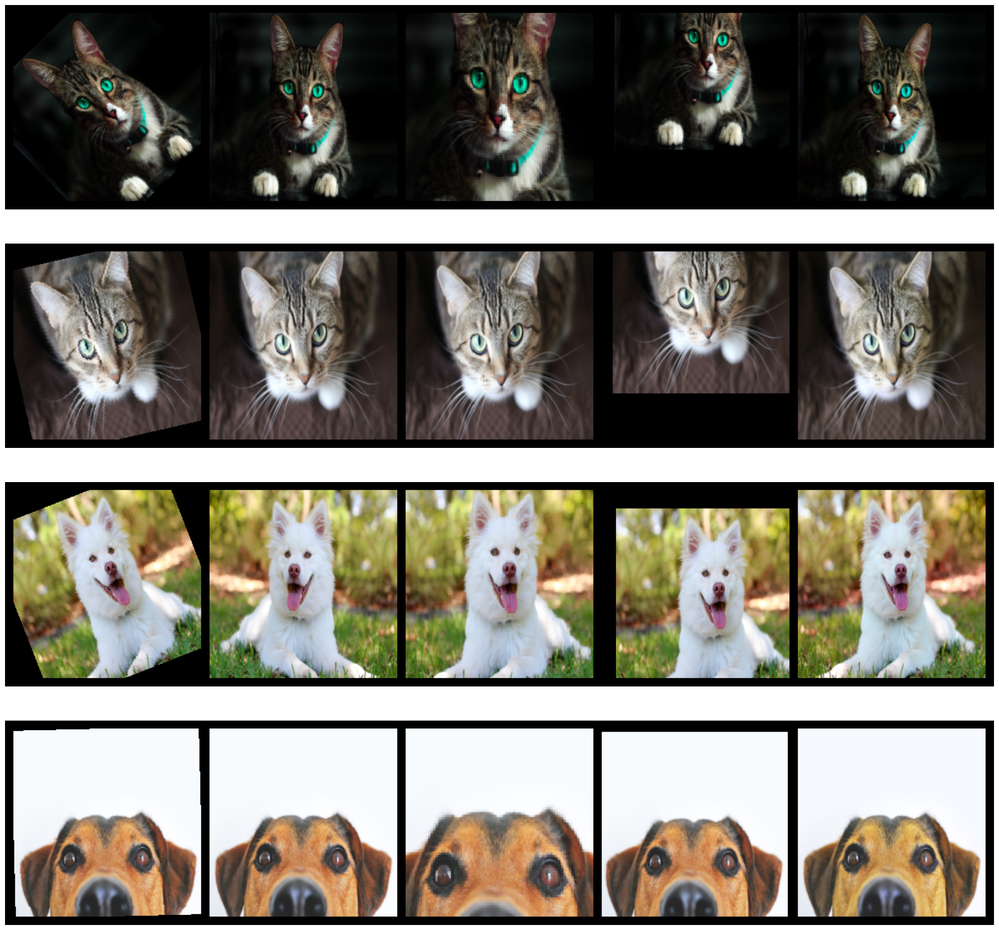

In [44]:
chunks = [images[i : i + 5] for i in range(0, 20, 5)]

fig, axes = plt.subplots(
    nrows=len(chunks),
    ncols=1,
    figsize=(20, 5 * len(chunks)),
)
for ax, chunk in zip(axes, chunks):
    batch = torch.stack(chunk, dim=0)
    grid = make_grid(batch, nrow=5, padding=10) 
    np_grid = grid.permute(1, 2, 0).cpu().numpy()
    ax.imshow(np_grid)
    ax.axis("off")
plt.tight_layout(h_pad=1.0)
plt.tight_layout()
plt.show()

### Transfer Learning

In [48]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [49]:
# Transforms: resize to 224, augment & normalize 
transform = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


# CIFAR-10 datasets & loaders
train_dataset = datasets.CIFAR10(
    root='../../datasets/', train=True, download=True, transform=transform
)
test_dataset = datasets.CIFAR10(
    root='../../datasets', train=False, download=True, transform=transform
)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False)

In [50]:
# Load pretrained ResNet-50
model = models.resnet50(pretrained=True)

# Transfer Learning-ის იდეაა გავყინოთ პარამეტრები (weights & bias), თავიდან განვსაზღვროთ ბოლო წრფივი ფენები 
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

# Replace final FC layer
num_classes = 10
model.fc = nn.Linear(model.fc.in_features, num_classes)

model = model.to(device)

In [51]:
# Hyperparameters
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)

In [ ]:
# Train მოხდება მხოლოდ ბოლო ფენაზე
model.train()
for epoch in range(5):
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1} loss: {running_loss/len(train_loader):.4f}")

In [ ]:
# Evaluate on test set
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        test_logits = model(inputs)                
        y_pred  = torch.softmax(test_logits, dim=1)
        y_pred  = y_pred.argmax(dim=1)   
        all_preds.extend(y_pred.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [ ]:
# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()